# Titanic: Exploratory Data Analysis

**Internship Task 2 · Data Analytics**

This notebook uses the Titanic ZIP file supplied for this task. It checks the data, documents each cleaning choice, summarizes survival patterns, and makes clear charts.

The work is descriptive: it compares groups in the data and does not build a prediction model or claim cause and effect.

## Task checklist

- Inspect the Titanic training data with Python.
- Check missing values and data types.
- Clean the data while keeping the original unchanged.
- Compare survival by sex and passenger class.
- Summarize the data and visualize patterns and correlations.
- Include the bonus survival-rate bar chart and heatmap.

## 1. Import the libraries

**Purpose:** Load the few tools used in the notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from zipfile import ZipFile

sns.set_theme(style="whitegrid")

## 2. Read the supplied ZIP file

**Purpose:** Use `train.csv`, the file in this ZIP that contains known survival outcomes. The test file has no survival column, so it is not used for this exploratory analysis.

In [2]:
zip_path = Path("titanic.zip")
if not zip_path.exists():
    zip_path = Path.home() / "Downloads" / "titanic.zip"

with ZipFile(zip_path) as zip_file:
    df_raw = pd.read_csv(zip_file.open("train.csv"))

print("ZIP file:", zip_path)
print("Rows and columns:", df_raw.shape)
display(df_raw.head())

ZIP file: titanic.zip
Rows and columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Learn what the columns mean

**Purpose:** Identify the outcome and the fields that can help explain survival.

In [3]:
column_meanings = pd.DataFrame({
    "Column": ["PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"],
    "Meaning": [
        "Passenger number", "Outcome: 0 = did not survive, 1 = survived", "Ticket class: 1, 2, or 3",
        "Passenger name", "Recorded sex", "Age in years", "Siblings or spouses aboard",
        "Parents or children aboard", "Ticket number", "Ticket fare", "Cabin number",
        "Port: C = Cherbourg, Q = Queenstown, S = Southampton"
    ]
})
display(column_meanings)
print("Data types in the source:")
display(df_raw.dtypes.to_frame("Type"))

,Column,Meaning
0,PassengerId,Passenger number
1,Survived,"Outcome: 0 = did not survive, 1 = survived"
2,Pclass,"Ticket class: 1, 2, or 3"
3,Name,Passenger name
4,Sex,Recorded sex
5,Age,Age in years
6,SibSp,Siblings or spouses aboard
7,Parch,Parents or children aboard
8,Ticket,Ticket number
9,Fare,Ticket fare


Data types in the source:


,Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


## 4. Check missing values and duplicates

**Purpose:** See the data issues before changing anything. The missing-value percentages are calculated from the original training file.

In [4]:
missing_count = df_raw.isna().sum()
missing_count = missing_count[missing_count > 0]
missing_percent = (missing_count / len(df_raw) * 100).round(1)

display(pd.DataFrame({"Missing rows": missing_count, "Missing percent": missing_percent}))
print("Duplicate rows:", df_raw.duplicated().sum())
print("Repeated passenger numbers:", df_raw["PassengerId"].duplicated().sum())

,Missing rows,Missing percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Duplicate rows: 0
Repeated passenger numbers: 0


## 5. Make a working copy

**Purpose:** Keep `df_raw` unchanged. All cleaning happens in `df_clean`.

In [5]:
df_clean = df_raw.copy()

## 6. Handle missing ages

**What is being cleaned:** 177 passengers have no age. Fill each missing age with the median age for passengers of the same sex and ticket class. If that group has no known ages, use the overall median. Keep a flag so we can still identify the originally missing ages.

In [6]:
df_clean["Age_was_missing"] = df_clean["Age"].isna().astype(int)

median_by_group = df_clean.groupby(["Sex", "Pclass"])["Age"].transform("median")
df_clean["Age"] = df_clean["Age"].fillna(median_by_group)
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

## 7. Handle missing cabin values

**What is being cleaned:** Cabin is missing for most passengers. Keep those passengers, mark which cabin values were missing, and label the missing cabin as `Unknown` instead of deleting a large part of the data.

In [7]:
df_clean["Cabin_was_missing"] = df_clean["Cabin"].isna().astype(int)
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")

## 8. Handle missing embarkation ports

**What is being cleaned:** Two passengers have no port recorded. Fill those cells with the most common port and keep a flag showing which rows were filled.

In [8]:
df_clean["Embarked_was_missing"] = df_clean["Embarked"].isna().astype(int)
most_common_port = df_clean["Embarked"].mode()[0]
df_clean["Embarked"] = df_clean["Embarked"].fillna(most_common_port)
print("Port used for the missing values:", most_common_port)

Port used for the missing values: S


## 9. Convert columns to suitable data types

**Purpose:** Treat group labels as categories and measurements/counts as numbers. `Survived` stays numeric 0/1 so its average is the survival rate.

In [9]:
df_clean["PassengerId"] = df_clean["PassengerId"].astype(int)
df_clean["Survived"] = df_clean["Survived"].astype(int)
df_clean["Pclass"] = df_clean["Pclass"].astype("category")
df_clean["Sex"] = df_clean["Sex"].astype("category")
df_clean["Cabin"] = df_clean["Cabin"].astype("category")
df_clean["Embarked"] = df_clean["Embarked"].astype("category")
df_clean["Age"] = pd.to_numeric(df_clean["Age"])
df_clean["Fare"] = pd.to_numeric(df_clean["Fare"])
df_clean["SibSp"] = df_clean["SibSp"].astype(int)
df_clean["Parch"] = df_clean["Parch"].astype(int)

display(df_clean.dtypes.to_frame("Clean type"))

,Clean type
PassengerId,int64
Survived,int64
Pclass,category
Name,str
Sex,category
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


## 10. Add simple family measures

**Purpose:** Combine the family counts already in the file. This lets us compare passengers travelling alone with passengers travelling in small or larger groups.

In [10]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

df_clean["FamilyGroup"] = pd.cut(
    df_clean["FamilySize"],
    bins=[0, 1, 3, 5, 20],
    labels=["Alone", "Small (2-3)", "Medium (4-5)", "Large (6+)"]
)
display(df_clean[["SibSp", "Parch", "FamilySize", "FamilyGroup", "IsAlone"]].head())

,SibSp,Parch,FamilySize,FamilyGroup,IsAlone
0,1,0,2,Small (2-3),0
1,1,0,2,Small (2-3),0
2,0,0,1,Alone,1
3,1,0,2,Small (2-3),0
4,0,0,1,Alone,1


## 11. Check the cleaned data

**Purpose:** Confirm the number of passengers stayed the same and review any remaining missing values.

In [11]:
print("Rows before cleaning:", len(df_raw))
print("Rows after cleaning:", len(df_clean))
print("Missing values after cleaning:")
display(df_clean.isna().sum().to_frame("Missing rows"))
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Rows before cleaning: 891
Rows after cleaning: 891
Missing values after cleaning:


,Missing rows
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Duplicate rows after cleaning: 0


## 12. Summary statistics

**Purpose:** Show the outcome balance and the range of the main numeric fields.

In [12]:
outcome_counts = df_clean["Survived"].value_counts().sort_index()
outcome_counts.index = ["Did not survive", "Survived"]
display(outcome_counts.to_frame("Passengers"))

print("Overall survival rate:", round(df_clean["Survived"].mean() * 100, 1), "%")
display(df_clean[["Age", "Fare", "SibSp", "Parch", "FamilySize"]].describe().T)

,Passengers
Did not survive,549
Survived,342


Overall survival rate: 38.4 %


,count,mean,std,min,25%,50%,75%,max
Age,891.0,29.112424,13.304424,0.42,21.5000,26.0000,36.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
FamilySize,891.0,1.904602,1.613459,1.00,1.0000,1.0000,2.0,11.0000


## 13. Compare survival by sex

**What is being compared:** Number of passengers, number of survivors, and survival rate for each sex. Since survival is coded 0 or 1, its average is the survival rate.

In [13]:
survival_by_sex = df_clean.groupby("Sex", observed=True)["Survived"].agg(
    Passengers="size", Survivors="sum", Survival_Rate="mean"
)
survival_by_sex["Survival_Rate"] = (survival_by_sex["Survival_Rate"] * 100).round(1)
display(survival_by_sex)

,Passengers,Survivors,Survival_Rate
Sex,,,
female,314,233,74.2
male,577,109,18.9


## 14. Compare survival by passenger class

**What is being compared:** The same measures for first, second, and third class.

In [14]:
survival_by_class = df_clean.groupby("Pclass", observed=True)["Survived"].agg(
    Passengers="size", Survivors="sum", Survival_Rate="mean"
)
survival_by_class["Survival_Rate"] = (survival_by_class["Survival_Rate"] * 100).round(1)
display(survival_by_class.sort_index())

,Passengers,Survivors,Survival_Rate
Pclass,,,
1,216,136,63.0
2,184,87,47.3
3,491,119,24.2


## 15. Compare sex and class together

**What is being compared:** Survival rates for each combination of sex and passenger class. This table is also used for the bonus heatmap.

In [15]:
survival_by_class_and_sex = df_clean.pivot_table(
    index="Pclass", columns="Sex", values="Survived", aggfunc="mean", observed=True
)
display((survival_by_class_and_sex * 100).round(1))

Sex,female,male
Pclass,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


## 16. Compare other passenger groups

**What is being compared:** Survival by embarkation port and by family-size group. These are additional group-based insights.

In [16]:
survival_by_port = df_clean.groupby("Embarked", observed=True)["Survived"].agg(
    Passengers="size", Survivors="sum", Survival_Rate="mean"
)
survival_by_port["Survival_Rate"] = (survival_by_port["Survival_Rate"] * 100).round(1)
display(survival_by_port)

survival_by_family = df_clean.groupby("FamilyGroup", observed=True)["Survived"].agg(
    Passengers="size", Survivors="sum", Survival_Rate="mean"
)
survival_by_family["Survival_Rate"] = (survival_by_family["Survival_Rate"] * 100).round(1)
display(survival_by_family)

,Passengers,Survivors,Survival_Rate
Embarked,,,
C,168,93,55.4
Q,77,30,39.0
S,646,219,33.9


,Passengers,Survivors,Survival_Rate
FamilyGroup,,,
Alone,537,163,30.4
Small (2-3),263,148,56.3
Medium (4-5),44,24,54.5
Large (6+),47,7,14.9


## 17. Chart: passenger outcomes

**Purpose:** Show how many passengers survived and did not survive.

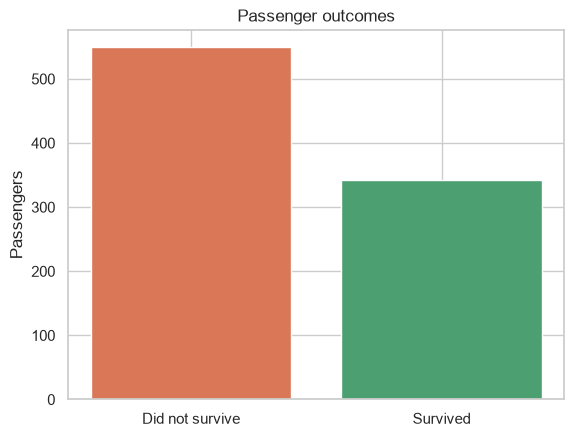

In [17]:
survival_counts = df_clean["Survived"].value_counts().sort_index()
plt.bar(["Did not survive", "Survived"], survival_counts.values, color=["#D97757", "#4C9F70"])
plt.title("Passenger outcomes")
plt.ylabel("Passengers")
plt.show()

## 18. Bonus chart: survival rate by sex

**Purpose:** Compare survival percentages for female and male passengers.

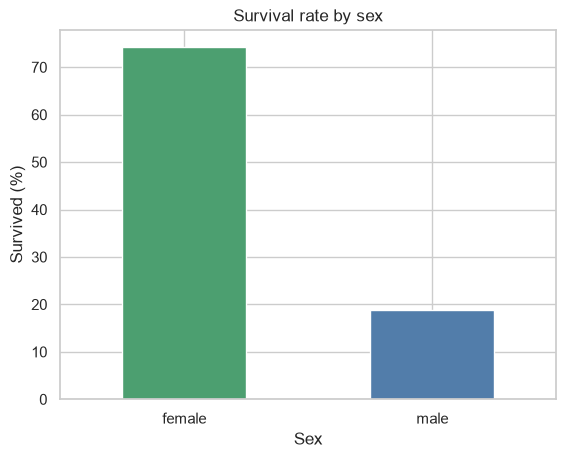

In [18]:
survival_rate_by_sex = df_clean.groupby("Sex", observed=True)["Survived"].mean() * 100
survival_rate_by_sex.plot(kind="bar", color=["#4C9F70", "#527DAA"])
plt.title("Survival rate by sex")
plt.ylabel("Survived (%)")
plt.xlabel("Sex")
plt.xticks(rotation=0)
plt.show()

## 19. Bonus chart: survival rate by class

**Purpose:** Compare survival percentages across first, second, and third class.

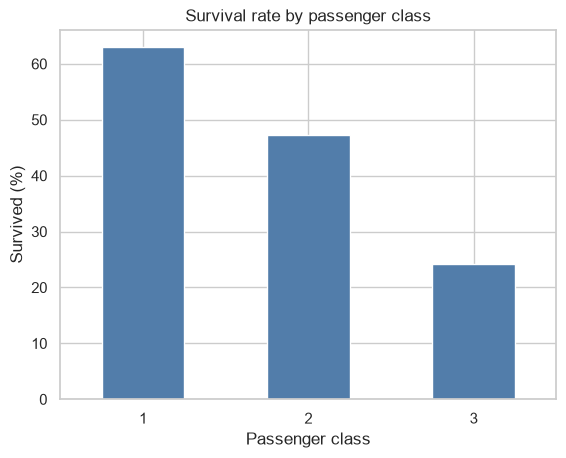

In [19]:
survival_rate_by_class = df_clean.groupby("Pclass", observed=True)["Survived"].mean() * 100
survival_rate_by_class.plot(kind="bar", color="#527DAA")
plt.title("Survival rate by passenger class")
plt.ylabel("Survived (%)")
plt.xlabel("Passenger class")
plt.xticks(rotation=0)
plt.show()

## 20. Bonus heatmap: survival rate by sex and class

**Purpose:** Put the combined comparison into one view. Each cell is a survival percentage.

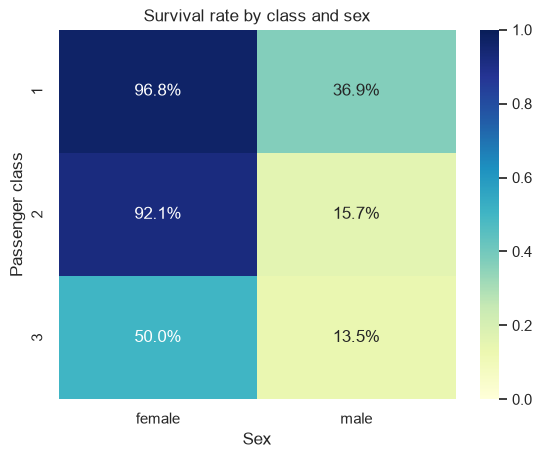

In [20]:
sns.heatmap(
    survival_by_class_and_sex,
    annot=True,
    fmt=".1%",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)
plt.title("Survival rate by class and sex")
plt.xlabel("Sex")
plt.ylabel("Passenger class")
plt.show()

## 21. Chart: missing values in the original data

**Purpose:** Make the original missingness visible. This chart uses `df_raw`, before any filling.

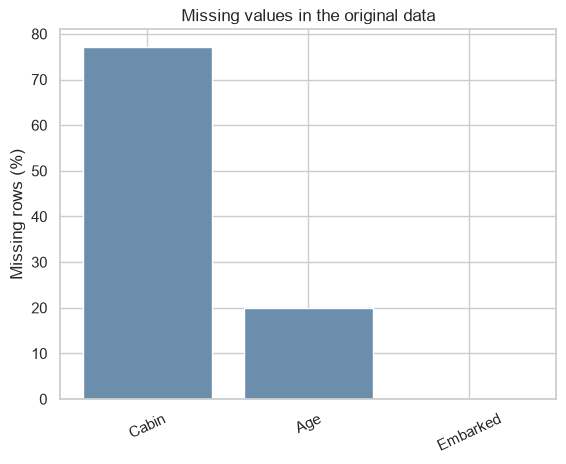

In [21]:
missing_percent = df_raw.isna().mean() * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

plt.bar(missing_percent.index, missing_percent.values, color="#6C8EAD")
plt.title("Missing values in the original data")
plt.ylabel("Missing rows (%)")
plt.xticks(rotation=25)
plt.show()

## 22. Chart: age and survival

**What is being compared:** Age distributions of passengers who survived and those who did not. Missing ages were filled earlier, and the missing-age flag remains in the cleaned data.

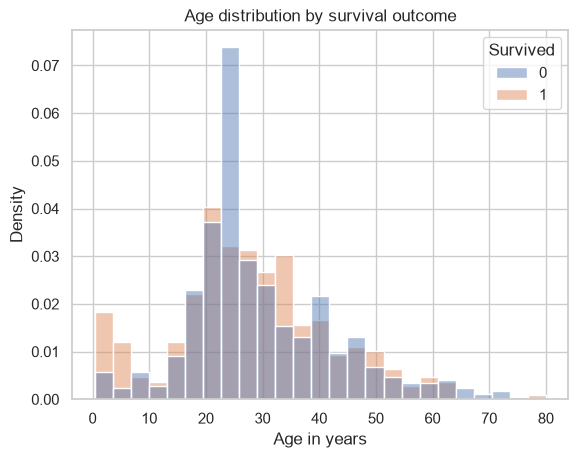

In [22]:
sns.histplot(
    data=df_clean,
    x="Age",
    hue="Survived",
    bins=25,
    stat="density",
    common_norm=False,
    alpha=0.45
)
plt.title("Age distribution by survival outcome")
plt.xlabel("Age in years")
plt.show()

## 23. Chart: fare, class, and survival

**What is being compared:** Fare distributions by passenger class and survival outcome. Outlier points are hidden only to make the box plots easier to read; no records are removed.

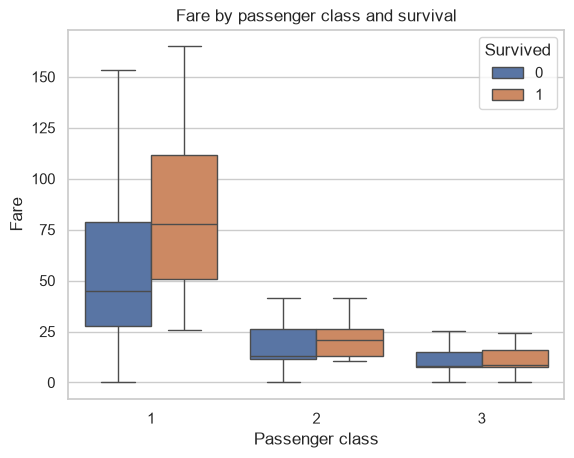

In [23]:
sns.boxplot(
    data=df_clean,
    x="Pclass",
    y="Fare",
    hue="Survived",
    showfliers=False
)
plt.title("Fare by passenger class and survival")
plt.xlabel("Passenger class")
plt.ylabel("Fare")
plt.show()

## 24. Correlations

**What is being compared:** Correlations between survival and selected numeric fields. Passenger class is converted to its 1–3 code for this chart, so treat that result as an ordinal pattern, not a measured distance. Correlation does not prove causation.

,Correlation with survival
Fare,0.257307
Parch,0.081629
FamilySize,0.016639
SibSp,-0.035322
Age,-0.059579
IsAlone,-0.203367
Pclass,-0.338481


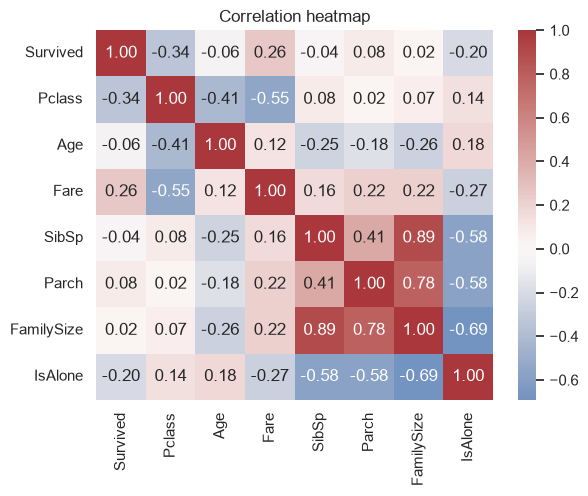

In [24]:
correlation_data = df_clean[[
    "Survived", "Pclass", "Age", "Fare", "SibSp", "Parch", "FamilySize", "IsAlone"
]].copy()
correlation_data["Pclass"] = correlation_data["Pclass"].astype(int)
correlation_matrix = correlation_data.corr()

display(correlation_matrix["Survived"].drop("Survived").sort_values(ascending=False).to_frame("Correlation with survival"))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation heatmap")
plt.show()

## 25. Main findings

**Purpose:** Print the main group comparisons from the tables above.

In [25]:
print("Overall survival rate:", round(df_clean["Survived"].mean() * 100, 1), "%")
print("\nSurvival rate by sex:")
print((df_clean.groupby("Sex", observed=True)["Survived"].mean() * 100).round(1))
print("\nSurvival rate by class:")
print((df_clean.groupby("Pclass", observed=True)["Survived"].mean() * 100).round(1))
print("\nThese are patterns in the sample. They do not prove that sex or class caused an outcome.")

Overall survival rate: 38.4 %

Survival rate by sex:
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by class:
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

These are patterns in the sample. They do not prove that sex or class caused an outcome.


## Limitations

- The analysis uses the 891 labeled rows in `train.csv`. `test.csv` is not used because it has no survival outcomes.
- Cabin is missing for many passengers, so cabin comparisons need caution.
- Filled age and port values are estimates; the missing-value flags preserve which rows were imputed.
- Group comparisons and correlations are descriptive, not causal.